# Bayesian Estimation vs Machine Learning

This notebook compares two approaches for estimating an unknown magnetic field from Ramsey measurement data:

1. **Random Forest regression**, which learns a mapping from measurement outcomes to field values.
2. **Bayesian estimation**, which calculates a posterior probability distribution for the field using the measurement likelihood and a prior.

The Bayesian method here is a fixed-protocol baseline using the same five interrogation times as the machine-learning dataset. It is not an exact reproduction of the paper's adaptive phase-estimation algorithm.

For a magnetic field B and interrogation time t, the probability of measuring the qubit in state ${(|1\rangle)}$, including exponential decoherence, is ${p_1(B,t)=\frac{1-e^{-t/T_2}\cos(\gamma Bt)}{2}.}$

For N independent shots, the number n of outcomes equal to 1 follows a binomial distribution:

${
P(n|B,t)=\binom{N}{n}p_1(B,t)^n[1-p_1(B,t)]^{N-n}.
}$

For measurements at several interrogation times, the likelihoods are multiplied, assuming independent measurement batches.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

gamma = 2*np.pi*28e9       
t2 = 1e-3                      
shots = 200
times = np.array([20, 50, 100, 200, 400]) * 1e-6

data_path = Path("C:\\Users\\HP\\Documents\\Github_Repo_Collection\\Quantum Magnetometry\\magnetometry_dataset.csv")
dataset = pd.read_csv(data_path)

feature_columns = ["P1_20us", "P1_50us", "P1_100us", "P1_200us", "P1_400us"]
X = dataset[feature_columns]
y = dataset["B_nT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [2]:
rf_model = RandomForestRegressor(n_estimators=300, max_features=1.0, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
n_compare = min(200, len(X_test))
X_compare = X_test.iloc[:n_compare]
y_compare = y_test.iloc[:n_compare].to_numpy()
rf_predictions = rf_model.predict(X_compare)

print("Number of test examples compared:", n_compare)

Number of test examples compared: 200


Bayes' theorem gives ${P(B|\mathbf{n}) \propto P(\mathbf{n}|B)P(B)}$
where ${(P(B))}$ is the prior and ${(P(\mathbf{n}|B))}$ is the likelihood of the observed counts.

We use a uniform prior over the simulated field interval, ${(0\leq B\leq100)}$ nT. The posterior mean is used as the Bayesian point estimate. Because the data file stores measured frequencies, we reconstruct the integer counts using ${(n_j=\mathrm{round}(N\hat p_j))}$.

In [3]:
B_grid_nT = np.linspace(0, 100, 2001)
B_grid_T = B_grid_nT*1e-9

def ramsey_probability(B_T, t, T2=t2, g=gamma):
    visibility = np.exp(-t/T2)
    return 0.5*(1 - visibility * np.cos(g*B_T*t))

def bayesian_estimate(measured_frequencies, s=shots):
    counts = np.rint(np.asarray(measured_frequencies)*s).astype(int)
    log_likelihood = np.zeros_like(B_grid_nT, dtype=float)

    for j, t in enumerate(times):
        p = ramsey_probability(B_grid_T, t)
        p = np.clip(p, 1e-12, 1 - 1e-12)
        n = counts[j]
        log_likelihood += n*np.log(p) + (s - n)*np.log(1 - p)

    log_posterior = log_likelihood - np.max(log_likelihood)
    posterior = np.exp(log_posterior)
    posterior /= np.sum(posterior)

    posterior_mean = np.sum(B_grid_nT*posterior)
    posterior_map = B_grid_nT[np.argmax(posterior)]
    return posterior_mean, posterior_map, posterior

We calculate a Bayesian posterior for each selected test example. The posterior mean is used for the main comparison; the maximum a posteriori (MAP) estimate is also retained.

In [4]:
bayes_means = []
bayes_maps = []

for _, row in X_compare.iterrows():
    mean_est, map_est, _ = bayesian_estimate(row[feature_columns].to_numpy())
    bayes_means.append(mean_est)
    bayes_maps.append(map_est)

bayes_means = np.asarray(bayes_means)
bayes_maps = np.asarray(bayes_maps)

print("Bayesian estimation complete.")

Bayesian estimation complete.


In [5]:
def regression_metrics(true_values, predictions):
    mae = mean_absolute_error(true_values, predictions)
    rmse = np.sqrt(mean_squared_error(true_values, predictions))
    return mae, rmse

rf_mae, rf_rmse = regression_metrics(y_compare, rf_predictions)
bayes_mae, bayes_rmse = regression_metrics(y_compare, bayes_means)

comparison = pd.DataFrame({"Method": ["Random Forest", "Bayesian posterior mean"], "MAE (nT)": [rf_mae, bayes_mae], 
                           "RMSE (nT)": [rf_rmse, bayes_rmse]})

display(comparison)

,Method,MAE (nT),RMSE (nT)
0,Random Forest,1.691316,2.381708
1,Bayesian posterior mean,1.470147,2.033242


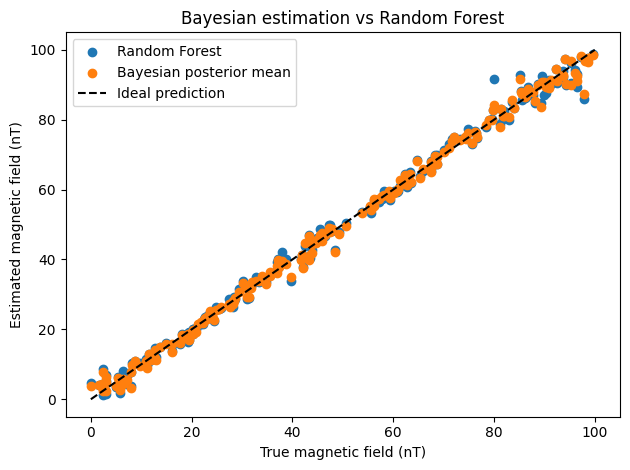

In [6]:
plt.scatter(y_compare, rf_predictions, label="Random Forest")
plt.scatter(y_compare, bayes_means, label="Bayesian posterior mean")
plt.plot([0, 100], [0, 100], "k--", label="Ideal prediction")
plt.xlabel("True magnetic field (nT)")
plt.ylabel("Estimated magnetic field (nT)")
plt.title("Bayesian estimation vs Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

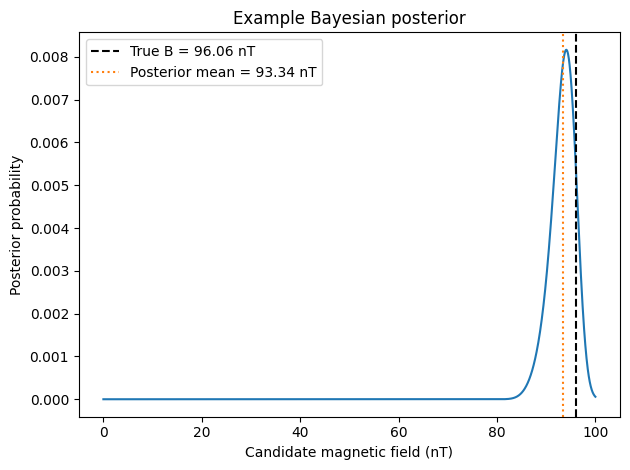

True field:        96.0586962506625  nT
Posterior mean:    93.33673048743978  nT
MAP estimate:      94.10000000000001  nT


In [7]:
example_frequencies = X_compare.iloc[0][feature_columns].to_numpy()
example_mean, example_map, example_posterior = bayesian_estimate(example_frequencies)
example_true = y_compare[0]

plt.plot(B_grid_nT, example_posterior)
plt.axvline(example_true, color="black", linestyle="--", label=f"True B = {example_true:.2f} nT")
plt.axvline(example_mean, color="tab:orange", linestyle=":", label=f"Posterior mean = {example_mean:.2f} nT")
plt.xlabel("Candidate magnetic field (nT)")
plt.ylabel("Posterior probability")
plt.title("Example Bayesian posterior")
plt.legend()
plt.tight_layout()
plt.show()

print("True field:       ", example_true, " nT")
print("Posterior mean:   ", example_mean, " nT")
print("MAP estimate:     ", example_map, " nT")

The comparison depends on the assumed prior, candidate-field interval, interrogation times, number of shots and decoherence model. The Bayesian baseline implemented here uses a fixed set of interrogation times and a uniform prior; it should not be described as an exact reproduction of the paper's adaptive algorithm.

Both methods are evaluated on data generated by the same model used to construct the dataset. Performance on real experimental data may differ.